In [25]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import polars as pl 
from tqdm import tqdm

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

In [26]:
bd.databases

Databases dictionary with 8 object(s):
	2026-3-19-11h18_processes_RE2020
	2026-4-21_consumptions_processes
	2026-4-22-15h1_buildings_RE2020
	2026-4-22-16h25_archetypes_RE2020_BB
	2026-4-22-16h7_buildings_cons_RE2020
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [16]:
builds_cons_db = bd.Database("2026-4-22-16h7_buildings_cons_RE2020")
builds_db = bd.Database("2026-4-22-15h1_buildings_RE2020")

In [17]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]
gwps

[('ecoinvent-3.11',
  'EF v3.1',
  'climate change',
  'global warming potential (GWP100)'),
 ('ecoinvent-3.11',
  'EN15804+A2 - Core impact categories and indicators',
  'climate change: total (EF v3.1 - IPCC 2021)',
  'global warming potential (GWP100)')]

In [18]:
b= [b for b in builds_cons_db if b["usage"]=="Logement collectif"][1]
b.as_dict()

{'name': '545556_1',
 'usage': 'Logement collectif',
 'unit': 'm2',
 'location': 'FR',
 'database': '2026-4-22-16h7_buildings_cons_RE2020',
 'code': '545556_1',
 'type': 'processwithreferenceproduct',
 'id': 305344802410815488}

In [30]:
cons_db = bd.Database("2026-4-21_consumptions_processes")
eau = cons_db.search("eau")[0]

lca = bc.LCA(demand = {eau : 28800}, method=gwps[0])
lca.lci()
lca.lcia()
lca.score

8650.688322616465

In [31]:
eau

'Consommations_eau' (cubic meter, FR, ('custom_process',))

In [38]:
b.edges()

In [19]:
list(b.production())

[Exchange: 1.0 m2 '545556_1' (m2, FR, None) to '545556_1' (m2, FR, None)]

In [20]:
list(b.edges())

[Exchange: 1.0 m2 '545556_1' (m2, FR, None) to '545556_1' (m2, FR, None),
 Exchange: 0.006397952655150352 unité 'Réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_Béton' (unité, FR, ('custom_process',)) to '545556_1' (m2, FR, None),
 Exchange: 0.09596928982725528 meter 'Gaines / fourreaux_Polypropylène' (meter, FR, ('custom_process',)) to '545556_1' (m2, FR, None),
 Exchange: 0.09596928982725528 meter 'Gaines / fourreaux_Polyéthylène' (meter, FR, ('custom_process',)) to '545556_1' (m2, FR, None),
 Exchange: 0.09596928982725528 meter 'Réseaux d’énergie_Câbles basse tension < 1kV' (meter, FR, ('custom_process',)) to '545556_1' (m2, FR, None),
 Exchange: 0.19193857965451055 meter 'Transfert d’énergie et de données à l’intérieur du bâtiment_Câbles de communication Cuivre et Fibres optiques' (meter, FR, ('custom_process',)) to '545556_1' (m2, FR, None),
 Exchange: 0.09596928982725528 meter 'Transfert d’énergie et de données à l’intérieur du bâtiment_Câbles de communica

In [21]:
lca = bc.LCA(demand = {b:1.0}, method=gwps[0])
lca.lci()
lca.lcia()

In [22]:
lca.score

1237.9263277627394

In [24]:
bwa.print_recursive_calculation(activity=b,lcia_method= gwps[0])

Fraction of score | Absolute score | Amount | Activity
0001 |  1238 |     1 | '545556_1' (m2, FR, None)
  0.0455 | 56.36 | 0.5338 | 'Eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_Bois' (m², FR, 
    0.0455 | 56.36 | 0.5338 | 'market for structural timber' (cubic meter, RER, None)
      0.04 | 49.56 | 0.5338 | 'structural timber production' (cubic meter, RER, None)
  0.0434 | 53.67 | 1.886 | 'Eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_Béton précontrai
    0.0227 | 28.12 | 0.09428 | 'market for concrete, 30MPa' (cubic meter, RoW, None)
      0.0108 | 13.39 | 0.0483 | 'concrete production, 30MPa, for drilled piles, with cement, CEM II/B' (cubic meter, RoW, None)
    0.0168 | 20.85 | 9.428 | 'market for reinforcing steel' (kilogram, GLO, None)
      0.0113 | 14.01 | 6.371 | 'reinforcing steel production' (kilogram, RoW, None)
  0.0261 | 32.36 | 1.226 | 'Petits éléments de maçonnerie_Terre cuite' (m², FR, ('c

# Comparaisons archetypes vs bdd avec energie

In [27]:
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import INPUT_PATHS

df_buildings = pl.read_csv(
    source=INPUT_PATHS["BUILDINGS"], ignore_errors=True
    )

In [15]:
def chunk_list(lst, chunk_size):
    for i in range(0, len(lst), chunk_size):
        yield lst[i:i + chunk_size]

In [ ]:
import gc
buildings_energy_res = {}
config ={"impact_categories" : gwps}

for chunk in tqdm(chunk_list(list(builds_energy_db),2000)):
    demands = {
        b["name"] : {b.id : 1.0 }
        for b in chunk
        }
    data_objs = bd.get_multilca_data_objs(
        functional_units=demands,
        method_config=config
        )
    lca = bc.MultiLCA(demands=demands, method_config=config, data_objs=data_objs)
    lca.lci()
    lca.lcia()
    buildings_energy_res |= lca.scores
    del lca
    del data_objs
    del demands
    gc.collect()

import pickle
today = datetime.today()
with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_res_per_building_cons.pkl", "wb") as f:
    pickle.dump(buildings_energy_res, f)

40it [1:19:41, 119.53s/it]


In [22]:
def ic_batiment_per_use(df) :
    usages = df.select(
        pl.col("usage_principal_1_txt").unique()
        ).drop_nulls()["usage_principal_1_txt"]


    return {
        u : df.filter(
            pl.col("usage_principal_1_txt")==u
            ).select("projet_id","batiment_index","ic_batiment").unique()["ic_batiment"]
            for u in usages
            }

dict_ic_batiment = ic_batiment_per_use(df_buildings)

In [24]:
df_ic_batiment = pl.DataFrame(schema={"usage" : pl.String,"value" : pl.Float64,"indicateur" : pl.String})
for u,v in dict_ic_batiment.items() :
    for value in v :
        new_row = pl.DataFrame(
            {
                "usage": u,
                "value" : value,
                "indicateur" : "RE2020"
            }
            )
        df_ic_batiment.extend(new_row)

In [27]:
usage_dict = {a["name"] : a["usage"] for a in builds_energy_db}

In [28]:
for k,v in tqdm(buildings_energy_res.items()) :
    
    new_row = pl.DataFrame(
    {
        "usage": usage_dict[k[1]],
        "value" : v,
        "indicateur" : str(k[0])
    }
    )
    df_ic_batiment.extend(new_row)

100%|██████████| 159288/159288 [00:07<00:00, 20435.81it/s]


In [30]:
from archetypes_re2020.data.remove_extreme_outliers import outliers

In [31]:
df_ic_batiment_filtered = pl.DataFrame(schema={"usage" : pl.String,"value" : pl.Float64,"indicateur" : pl.String,"mild_outliers" : pl.Boolean,"extreme_outliers" : pl.Boolean})

for usage in df_ic_batiment["usage"].drop_nulls().unique() :
    for ind in df_ic_batiment["indicateur"].unique() :
        tmp = df_ic_batiment.filter(
            pl.col("usage") == usage,
            pl.col("indicateur") == ind,
        ).drop_nulls()
        df_tmp = outliers(tmp,"value")

        df_ic_batiment_filtered = pl.concat([df_ic_batiment_filtered,df_tmp])
        

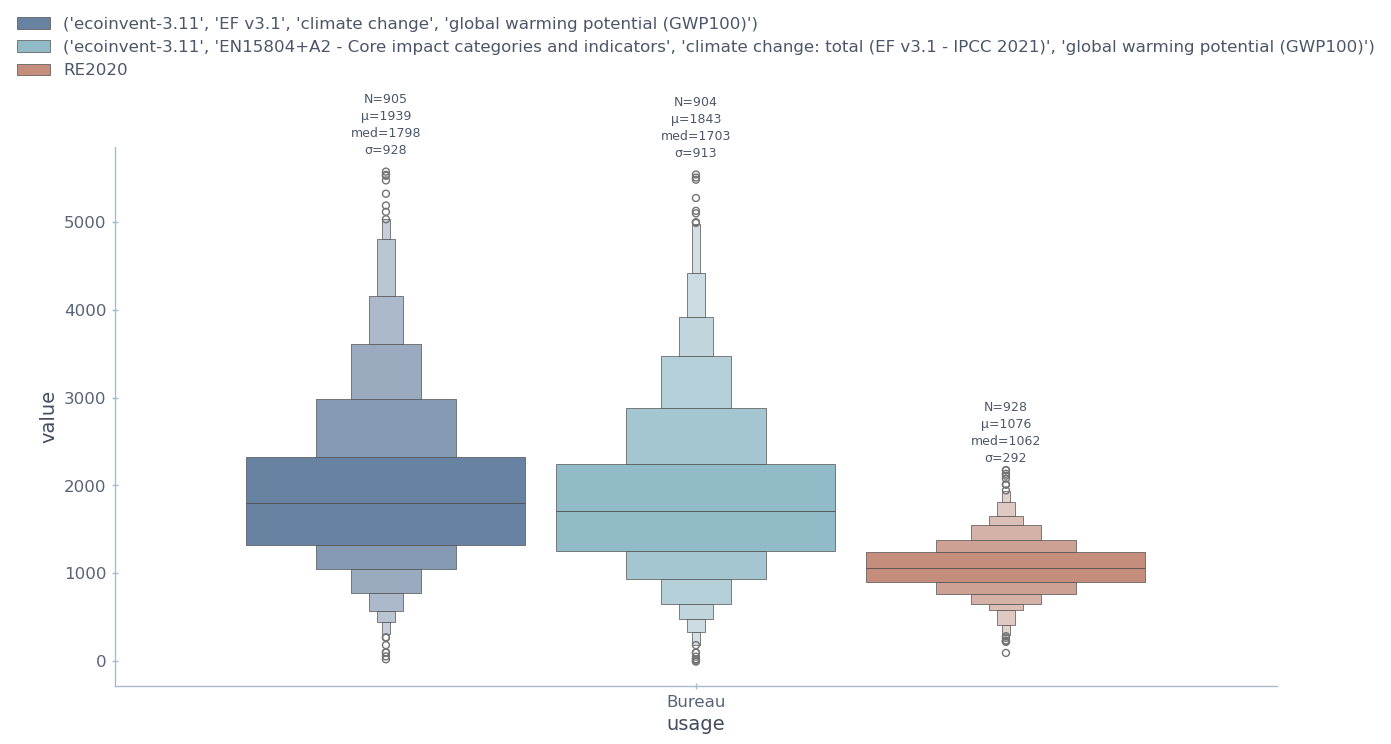

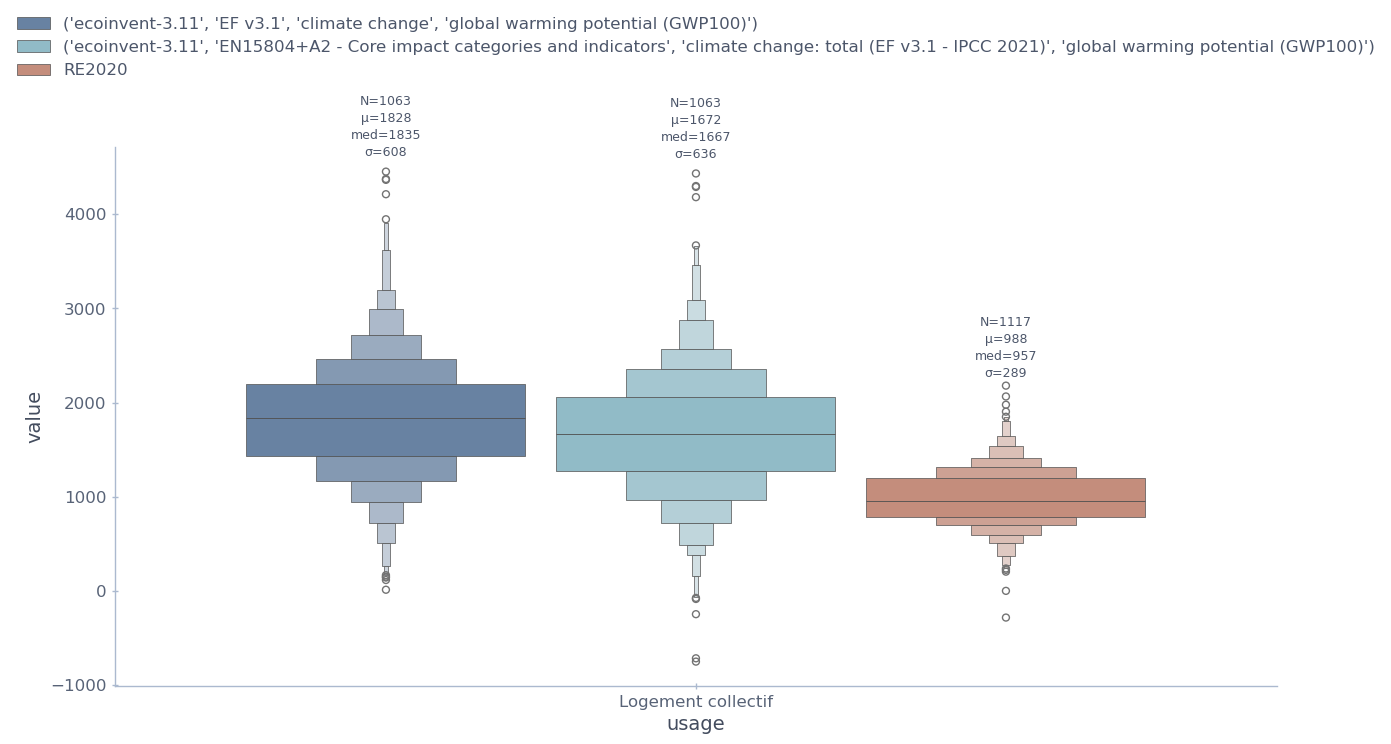

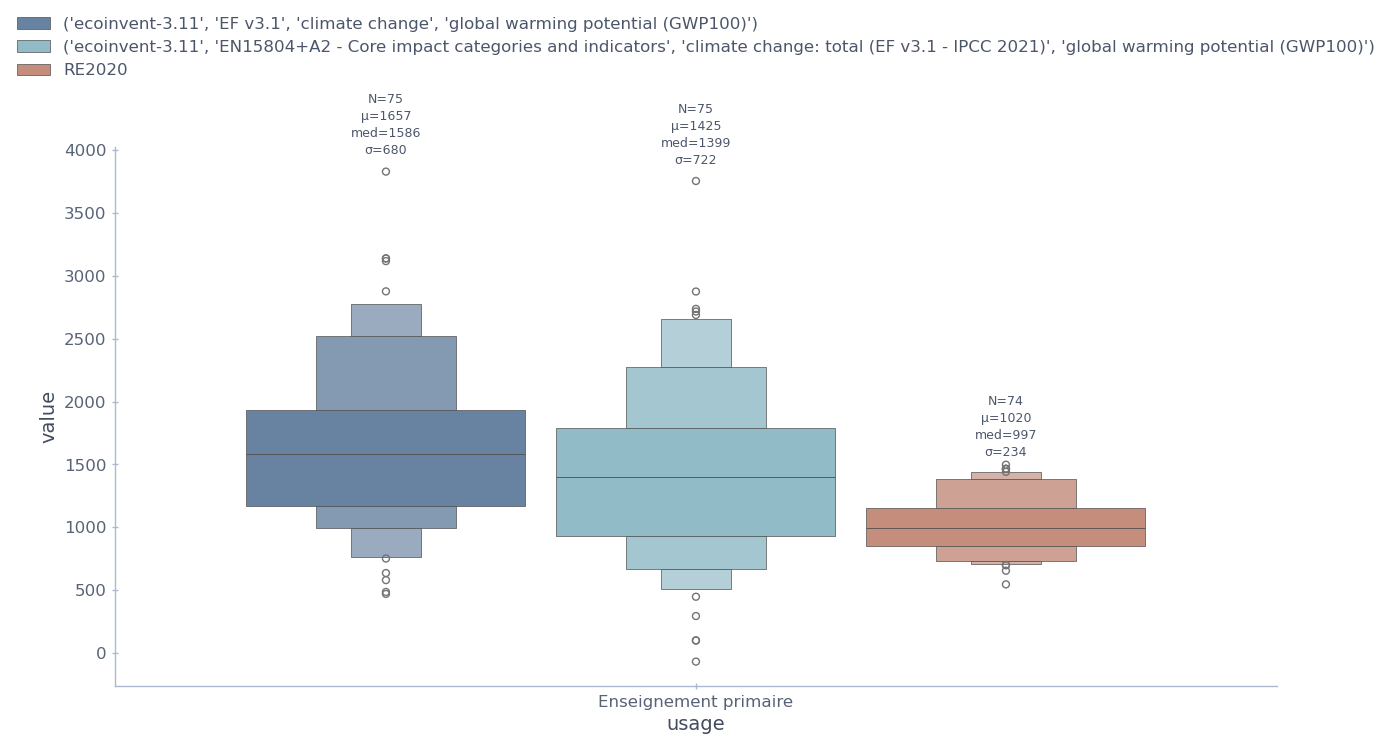

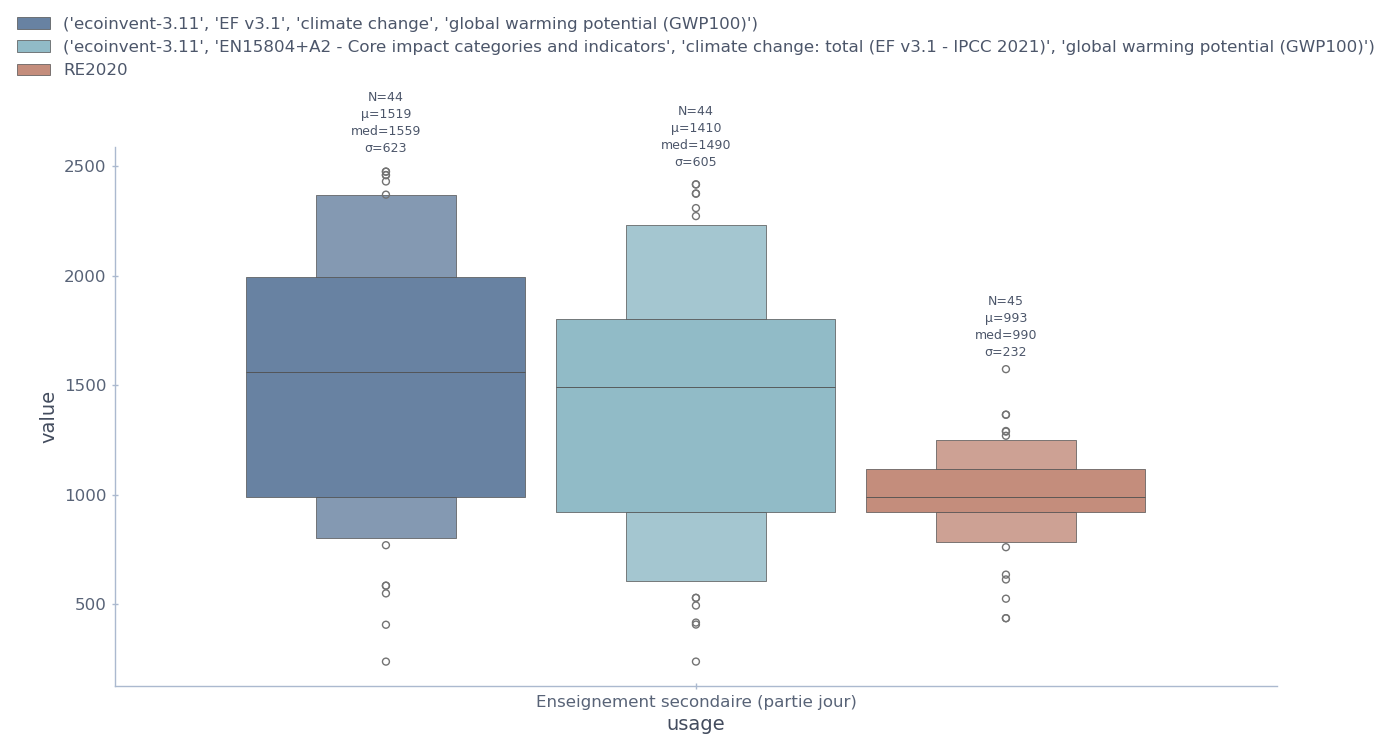

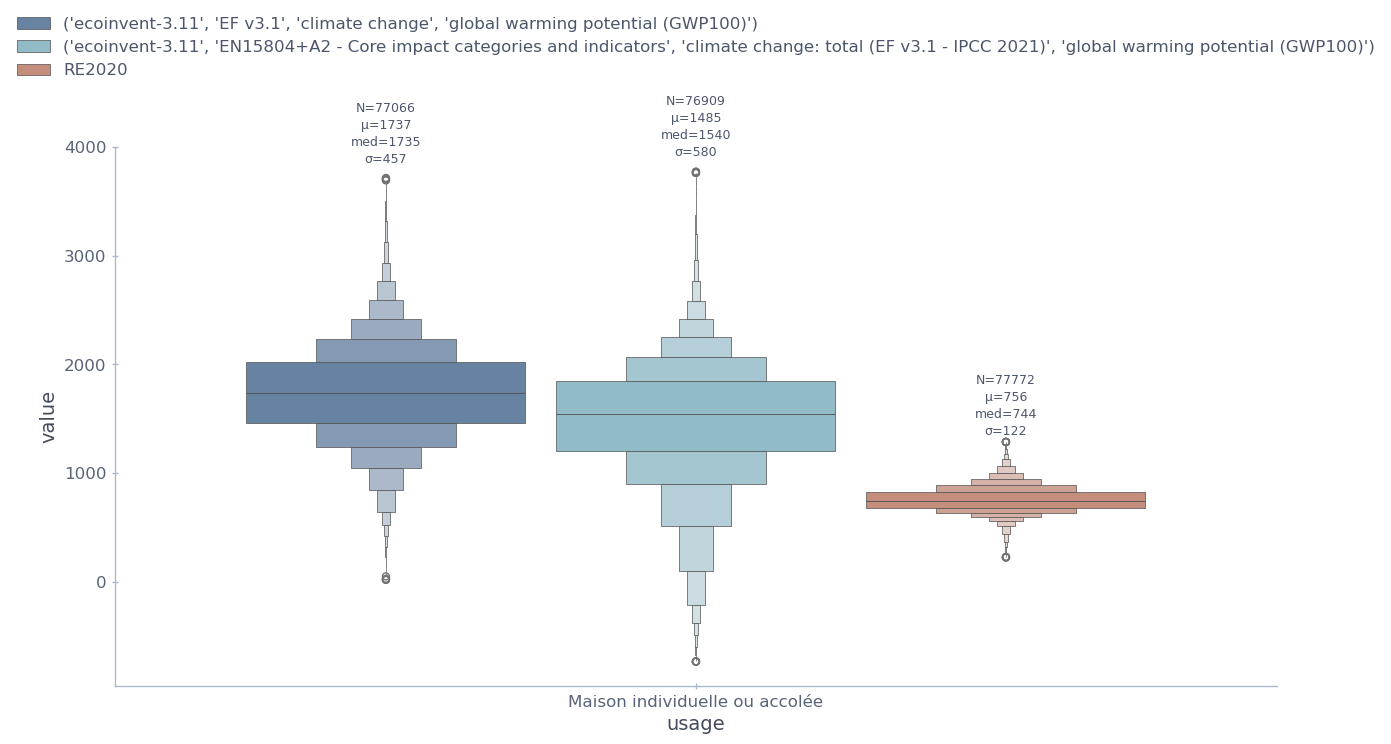

In [32]:
title = "comparaison_modele_vs_RE2020_energy_included"

from datetime import datetime
today = datetime.today()

import simplstyles
plt.style.use("nord-light")


for usage in df_ic_batiment_filtered['usage'].unique() :

    to_graph = df_ic_batiment_filtered.filter(
        pl.col("extreme_outliers") == False,
        # pl.col("mild_outliers") == False,
        pl.col("usage") == usage
        ).to_pandas()

    usages = to_graph["usage"].unique()
    indicateurs = to_graph["indicateur"].unique()
    n_ind = len(indicateurs)

    hue_order = sorted(indicateurs)  # seaborn sorts hue by default
    x_positions = {usage: i for i, usage in enumerate(sorted(usages))}

    fig, ax = plt.subplots(figsize = (15,7))

    sns.boxenplot(data=to_graph, 
        x = "usage",
        y = "value",
        hue = "indicateur",
        gap=.1,
        hue_order = hue_order
        )

    # plt.xticks(rotation=45, ha='right');
    plt.style.use("nord-light")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5,1.1))


    width = 0.8  
    offsets = [(j - (n_ind - 1) / 2) * (width / n_ind) for j in range(n_ind)]

    for j, ind in enumerate(hue_order):
        for usage in sorted(usages):
            subset = to_graph[
                (to_graph["usage"] == usage) &
                (to_graph["indicateur"] == ind)
            ]["value"].dropna()

            if len(subset) == 0:
                continue

            mean_val = subset.mean()
            median_val = subset.median()
            std_val = subset.std()

            x = x_positions[usage] + offsets[j]
            y_max = 1.03*subset.max() # place text just above 99th percentile

            ax.text(
                x, y_max,
                f"N={len(subset)}\nμ={mean_val:.0f}\nmed={median_val:.0f}\nσ={std_val:.0f}",
                ha='center', va='bottom',
                fontsize=9,
                color="#4c566a",
                linespacing=1.4
            )


    plt.savefig(
        f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}_{usage}.pdf",
        dpi=300,
        bbox_inches = "tight"
        )

## Tracé des différences

In [34]:
to_compare = df_buildings.select("projet_id","batiment_index","ic_batiment").unique()
df_ic_batiment_diff = pl.DataFrame(schema={"usage" : pl.String,"value" : pl.Float64,"indicateur" : pl.String})

for k,v in tqdm(buildings_energy_res.items()) :
    b_id = float(k[1].split("_")[1])
    p_id = float(k[1].split("_")[0])
    try :
        value_re2020 = to_compare.filter(pl.col("projet_id") == p_id, pl.col("batiment_index")==b_id)["ic_batiment"][0]
        new_row = pl.DataFrame(
        {
            "usage": usage_dict[k[1]],
            "value" : v-value_re2020,
            "indicateur" : f"{str(k[0])} - RE2020"
        }
        )
        df_ic_batiment_diff.extend(new_row)
    except IndexError :
        # print(f"Problème avec {k}")
        continue

100%|██████████| 159288/159288 [01:38<00:00, 1621.85it/s]


In [35]:

df_ic_batiment_diff_filtered = pl.DataFrame(schema={"usage" : pl.String,"value" : pl.Float64,"indicateur" : pl.String,"mild_outliers" : pl.Boolean,"extreme_outliers" : pl.Boolean})

for usage in df_ic_batiment_diff["usage"].drop_nulls().unique() :
    for ind in df_ic_batiment_diff["indicateur"].unique() :
        tmp = df_ic_batiment_diff.filter(
            pl.col("usage") == usage,
            pl.col("indicateur") == ind,
        ).drop_nulls()
        df_tmp = outliers(tmp,"value")

        df_ic_batiment_diff_filtered = pl.concat([df_ic_batiment_diff_filtered,df_tmp])

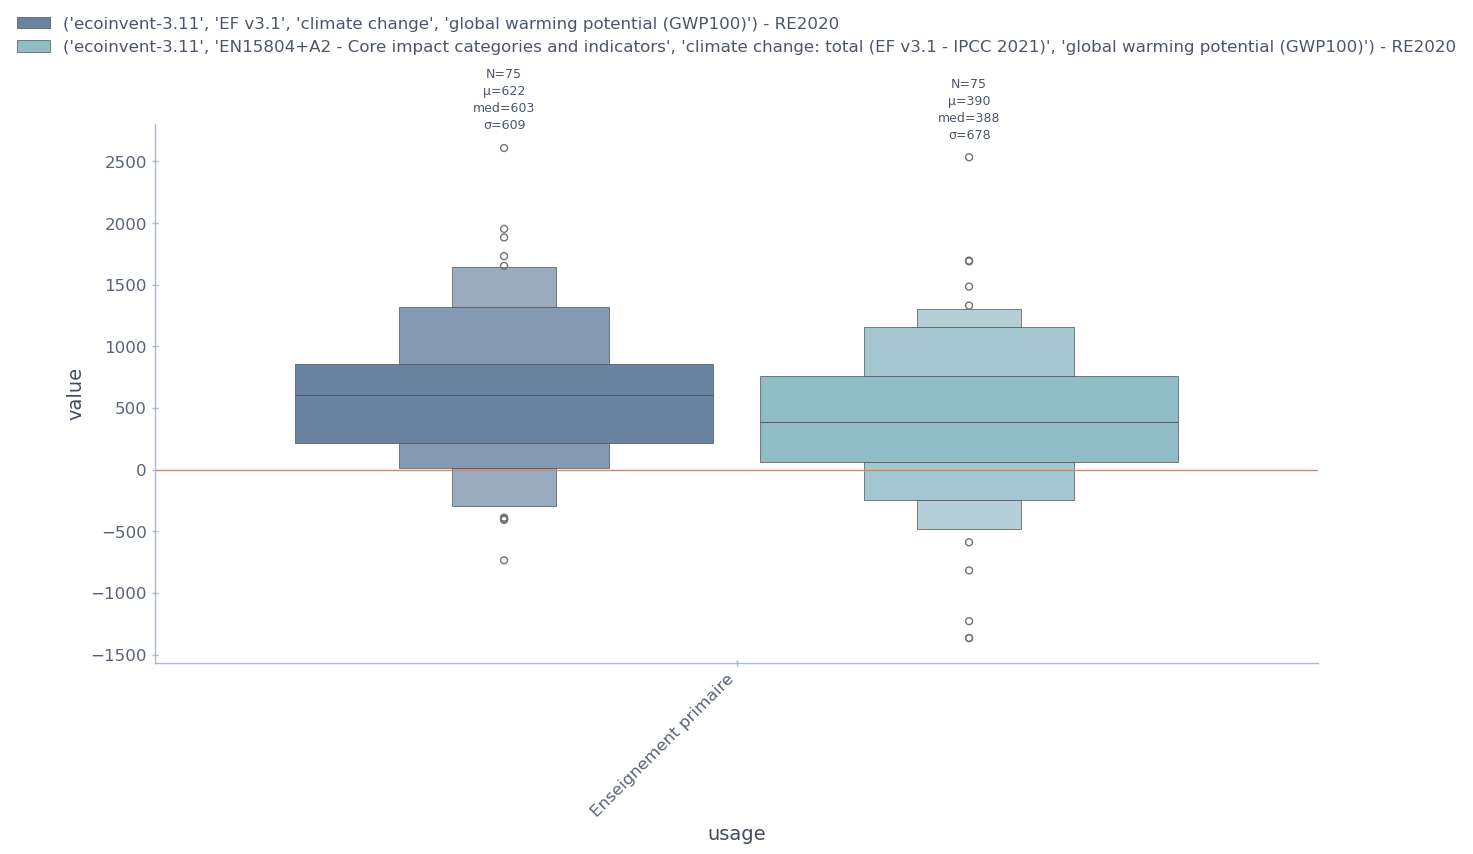

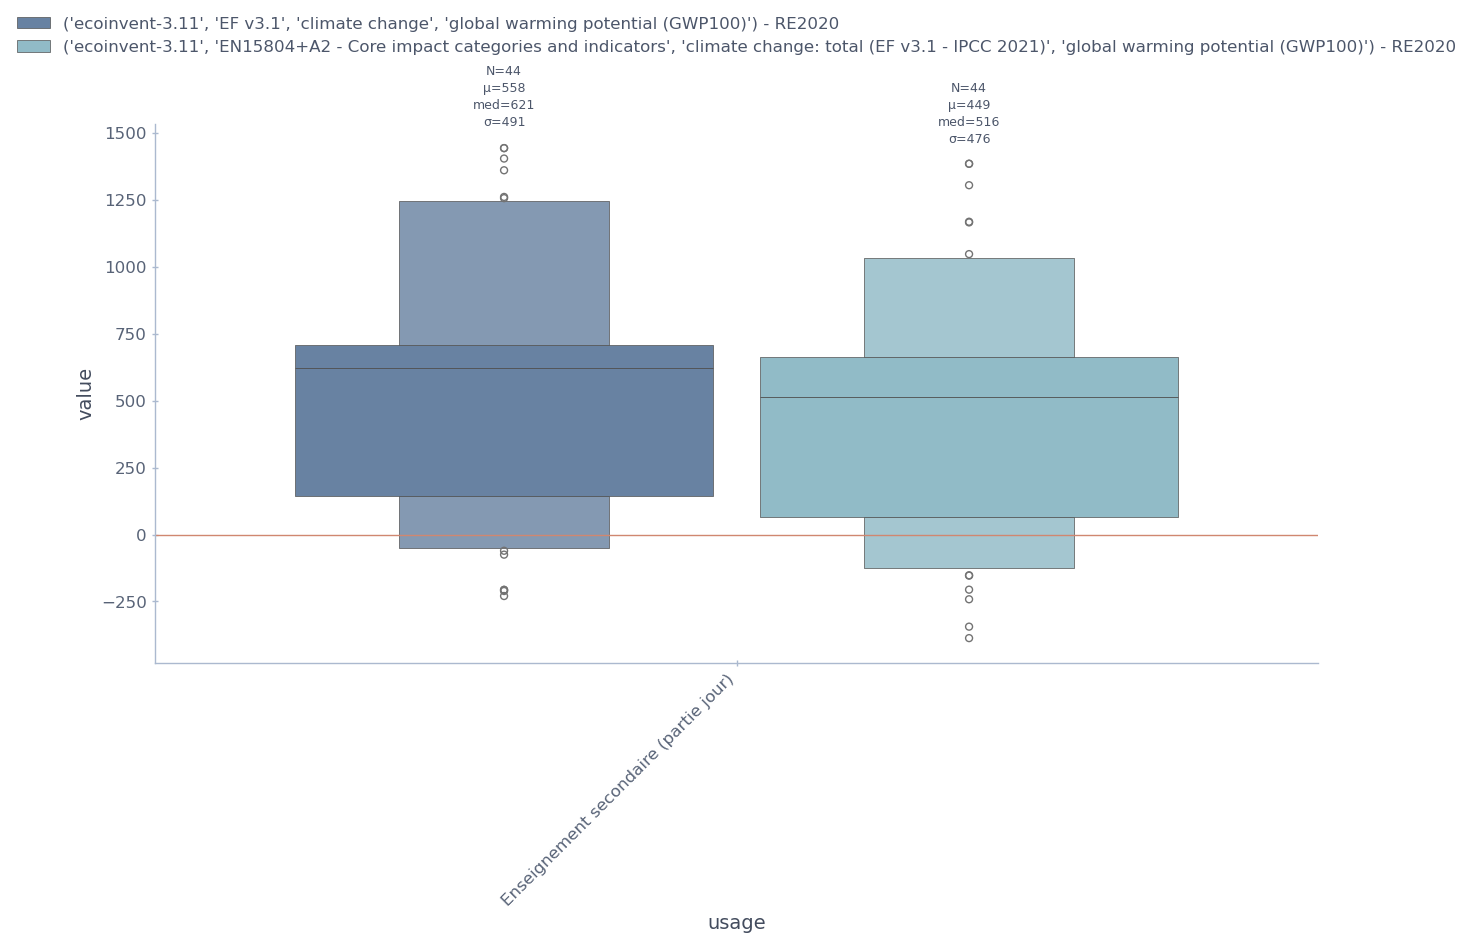

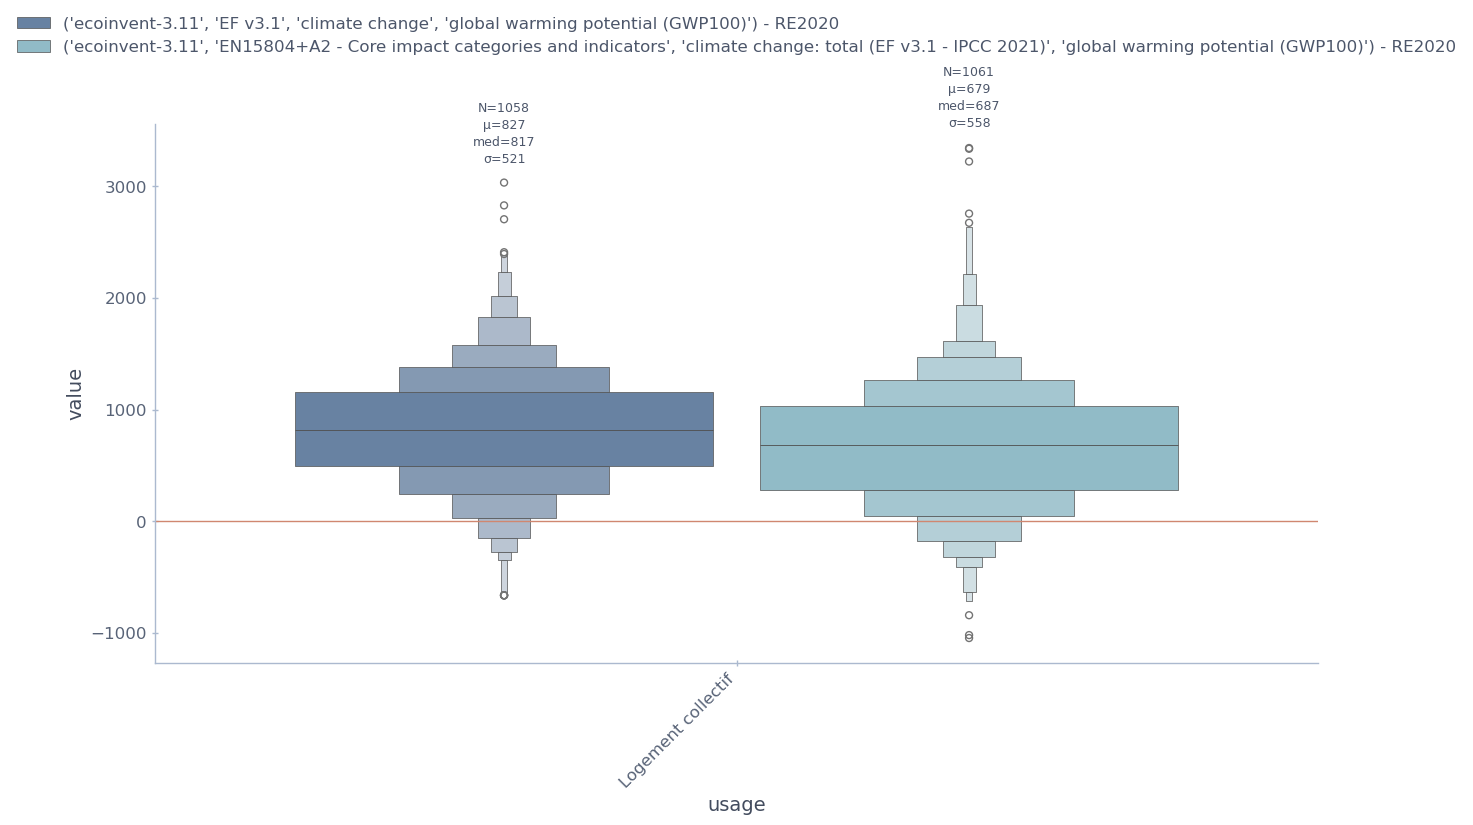

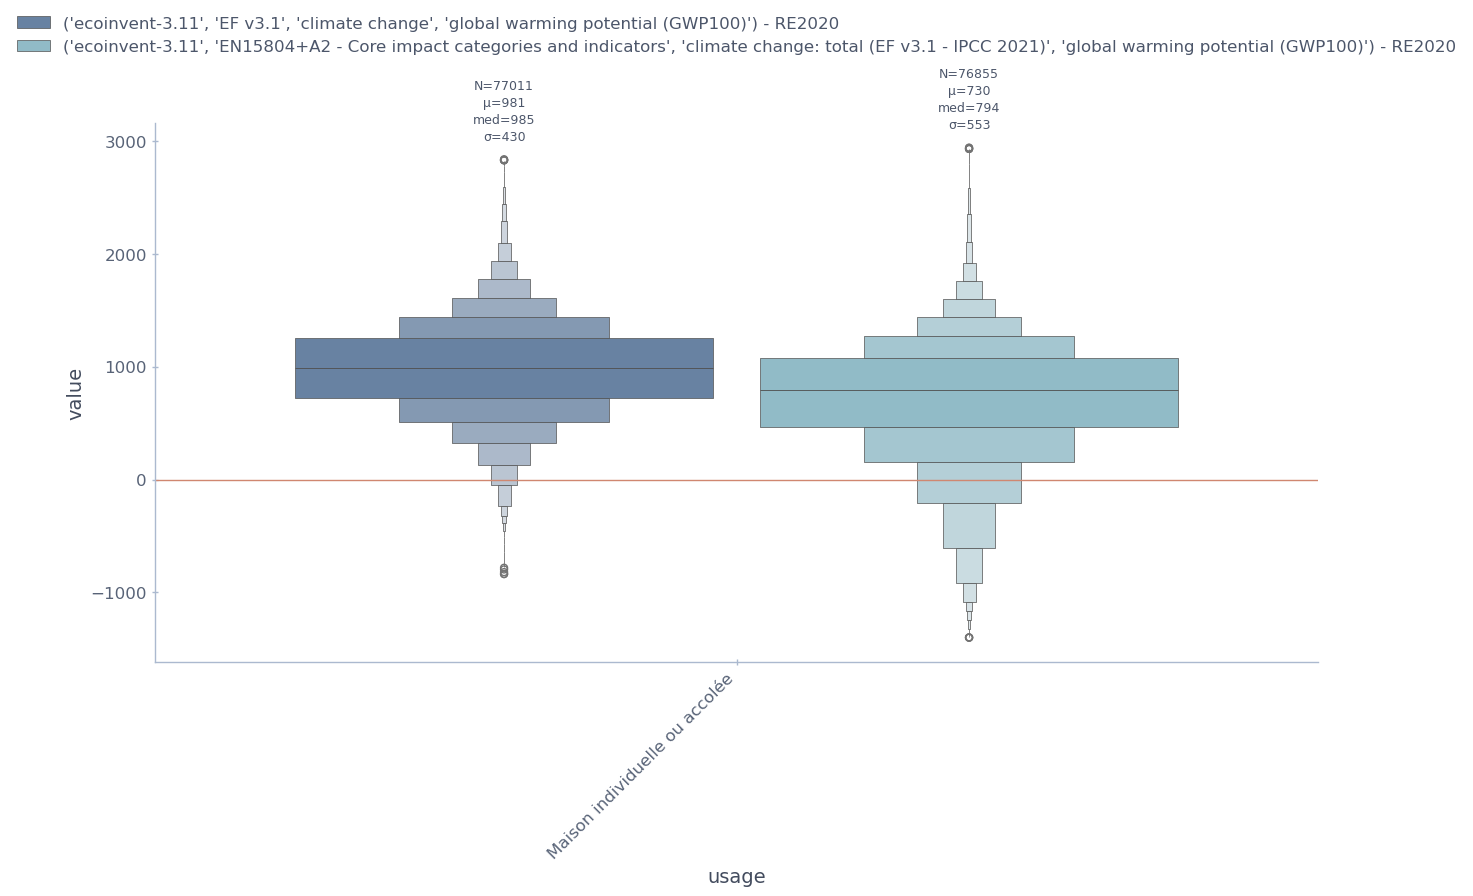

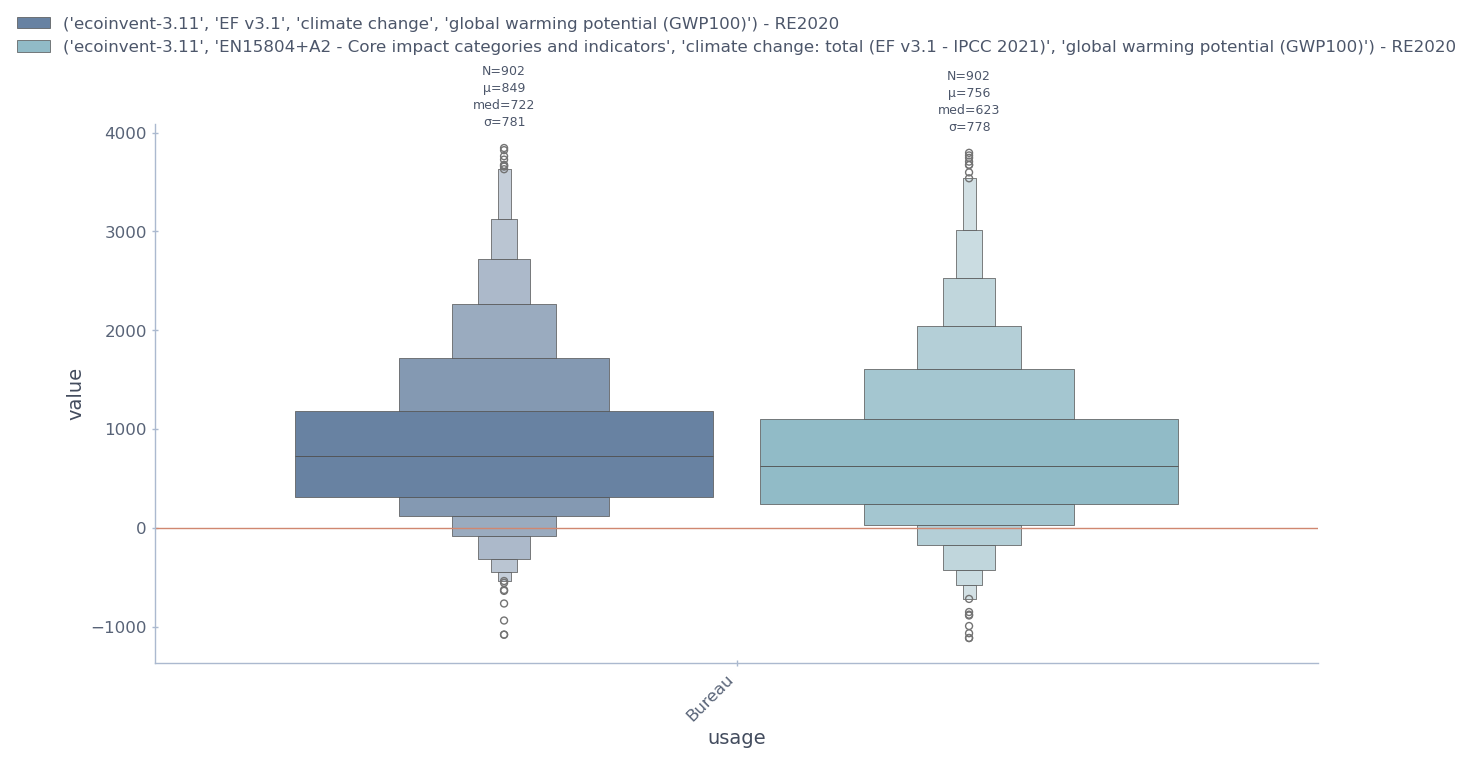

In [36]:
title = "comparaison_modele_vs_RE2020_energy_included_difference"


from datetime import datetime
today = datetime.today()

for usage in df_ic_batiment_diff_filtered["usage"].unique() :

    to_graph = df_ic_batiment_diff_filtered.filter(
        pl.col("extreme_outliers") ==False,
        pl.col("usage") == usage
        ).to_pandas()


    usages = to_graph["usage"].unique()
    indicateurs = to_graph["indicateur"].unique()
    n_ind = len(indicateurs)

    # Map hue order to x-offset (mimics seaborn's internal dodge)
    hue_order = sorted(indicateurs)  # seaborn sorts hue by default
    x_positions = {usage: i for i, usage in enumerate(sorted(usages))}

    fig, ax = plt.subplots(figsize = (15,7))
    ax.axhline(0,color="#d08770")

    sns.boxenplot(data=to_graph, 
        x = "usage",
        y = "value",
        hue = "indicateur",
        hue_order = hue_order,
        order = list(sorted(usages)),
        gap=.1
        )

    plt.xticks(rotation=45, ha='right');
    plt.style.use("nord-light")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5,1.1))

    width = 0.8  
    offsets = [(j - (n_ind - 1) / 2) * (width / n_ind) for j in range(n_ind)]

    for j, ind in enumerate(hue_order):
        for usage in sorted(usages):
            subset = to_graph[
                (to_graph["usage"] == usage) &
                (to_graph["indicateur"] == ind)
            ]["value"].dropna()

            if len(subset) == 0:
                continue

            mean_val = subset.mean()
            median_val = subset.median()
            std_val = subset.std()

            x = x_positions[usage] + offsets[j]
            y_max = 1.05*subset.max()  # place text just above 99th percentile

            ax.text(
                x, y_max,
                f"N={len(subset)}\nμ={mean_val:.0f}\nmed={median_val:.0f}\nσ={std_val:.0f}",
                ha='center', va='bottom',
                fontsize=9,
                color="#4c566a",
                linespacing=1.4
            )

    plt.savefig(
        f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}_{usage}.pdf",
        dpi=300,
        bbox_inches = "tight"
        )

#